In [2]:
import glob, pickle, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['pdf.fonttype'] = 42

In [3]:
Fs = 3e4

in_path = './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/'
files_to_analyze = glob.glob(in_path + '*_EncodingModel.pickle')

#comment this out to run all units-not just selected
selected_ids = set(pd.read_csv('./dataFolder/5_1DCompModel/selectedUnits.csv')
                   .dropna(subset=['status'])['mothID'].tolist())
files_to_analyze = [fp for fp in files_to_analyze 
                    if "_".join(os.path.basename(fp).split('_')[0:3]) in selected_ids]

print('selected units:', sorted(selected_ids))

selected units: ['m11_unit_2', 'm11_unit_3', 'm23_unit_1', 'm29_unit_1', 'm30_unit_1', 'm31_unit_1', 'm31_unit_2', 'm31_unit_3']


In [4]:
files_to_analyze

['./dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m31_unit_3_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m31_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m31_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m11_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m23_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m30_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m29_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m11_unit_3_EncodingModel.pickle']

In [5]:
time_up = []
time_down = []
mothID = []

for fp in files_to_analyze:
    ID = "_".join(os.path.basename(fp).split('_')[0:3])
    
    with open(fp, 'rb') as f:
        data = pickle.load(f)
        sta = np.asarray(data[1]).ravel() # index 1 = STA (660 samples)
        prior = np.asarray(data[4]).ravel()
        prior_error = np.asarray(data[5]).ravel()
        
    pre_sta = sta[:600]
    pre_prior = prior[:600] 
    pre_error = prior_error[:600]
    
    ## detect where sta crosses prior error for the first time
    up = np.where(pre_sta > pre_prior + pre_error)[0]
    down = np.where(pre_sta < pre_prior - pre_error)[0]
    
    if len(up) == 0:
        print('sta does not cross prior error - down direction')
        time_up.append(np.nan)
    else:
        first_time_cross = up[0]
        delay_in_sec = (600 - first_time_cross)*(1/3e4)
        time_up.append(delay_in_sec) 
    
    if len(down) == 0:
        print('sta does not cross prior error - down direction')
        time_down.append(np.nan)
    else:
        first_time_cross = down[0]
        delay_in_sec = (600 - first_time_cross)*(1/3e4)
        time_down.append(delay_in_sec)
    
    mothID.append(ID)

data = pd.DataFrame({'mothID': mothID,
             'time_up': time_up,
             'time_down': time_down})
data['merged'] = data['time_up'].fillna(data['time_down'])
out_path = './dataFolder/5b_Latency/selectedUnits/'
os.makedirs(out_path, exist_ok=True)
data.to_csv(out_path + 'time_to_spike.csv')

print(data)

sta does not cross prior error - down direction
sta does not cross prior error - down direction
sta does not cross prior error - down direction
sta does not cross prior error - down direction
sta does not cross prior error - down direction
sta does not cross prior error - down direction
sta does not cross prior error - down direction
sta does not cross prior error - down direction
       mothID   time_up  time_down    merged
0  m31_unit_3       NaN   0.001900  0.001900
1  m31_unit_2       NaN   0.002533  0.002533
2  m31_unit_1       NaN   0.001233  0.001233
3  m11_unit_2  0.003067        NaN  0.003067
4  m23_unit_1  0.001333        NaN  0.001333
5  m30_unit_1       NaN   0.001400  0.001400
6  m29_unit_1  0.001833        NaN  0.001833
7  m11_unit_3  0.000967        NaN  0.000967


In [6]:
median_ms = data['merged'].median() * 1000
print(f'median latency: {median_ms:.3f} ms')

print(f'mean latency: {data["merged"].mean() * 1000:.3f} ms')

median latency: 1.617 ms
mean latency: 1.783 ms


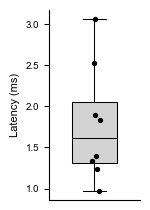

In [23]:
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(1.6, 2.2))
#converted here to ms
latency_ms = data['merged'].values * 1000

ax.boxplot(latency_ms,
           widths=0.5,
           patch_artist=True,
           showfliers=False,
           boxprops=dict(facecolor='lightgrey', edgecolor='black', linewidth=0.75),
           medianprops=dict(color='black', linewidth=0.75),
           whiskerprops=dict(color='black', linewidth=0.75),
           capprops=dict(color='black', linewidth=0.75))

x_jit = 1 + rng.normal(0, 0.05, size=len(latency_ms))
ax.scatter(x_jit, latency_ms, s=8, edgecolor='black', facecolor='black', zorder=3)

ax.set_ylabel('Latency (ms)', fontsize=8)
ax.set_xticks([])
ax.tick_params(labelsize=7, width=0.75)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig_out = './dataFolder/Figures/5b_Latency/selectedUnits/'
os.makedirs(fig_out, exist_ok=True)
plt.tight_layout()
fig.savefig(fig_out + 'time_to_spike_boxplot.pdf', bbox_inches='tight')
plt.show()

In [119]:
# plot latency to fire as the first time it crosses prior error
import seaborn as sns

latency = pd.read_csv('./dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/time_delay_first_cross.csv')

ModuleNotFoundError: No module named 'seaborn'

In [113]:
plot_data = latency['merged']
print(plot_data.median(), plot_data.mean(), plot_data.std())

0.0018 0.00179999999999998 0.00045338235029120414


In [126]:
plot_data.values
cleaned_data = plot_data.values[~np.isnan(plot_data.values)]

In [127]:
cleaned_data

array([0.00136667, 0.0018    , 0.00143333, 0.0025    , 0.0019    ])

{'whiskers': [<matplotlib.lines.Line2D at 0x298431fec30>,
 'caps': [<matplotlib.lines.Line2D at 0x298431fef90>,
 'boxes': [<matplotlib.lines.Line2D at 0x298431fe810>],
 'medians': [<matplotlib.lines.Line2D at 0x298431ff590>],
 'fliers': [<matplotlib.lines.Line2D at 0x298431ff6e0>],
 'means': []}

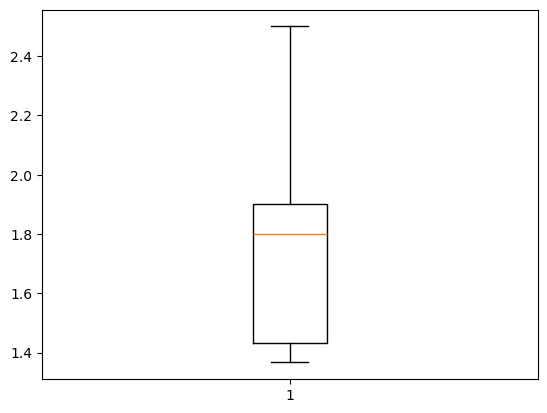

In [130]:
plt.boxplot(cleaned_data*1000)

In [99]:
fp = './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2\\m31_unit_1_EncodingModel.pickle'
ID = "_".join(os.path.basename(fp).split('_')[0:3])
    
with open(fp, 'rb') as f:
    data = pickle.load(f)
    sta = np.asarray(data[1]).ravel() # index 1 = STA (660 samples)
    prior = np.asarray(data[4]).ravel()
    prior_error = np.asarray(data[5]).ravel()

pre_sta = sta[:600]
pre_prior = prior[:600] 
pre_error = prior_error[:600]

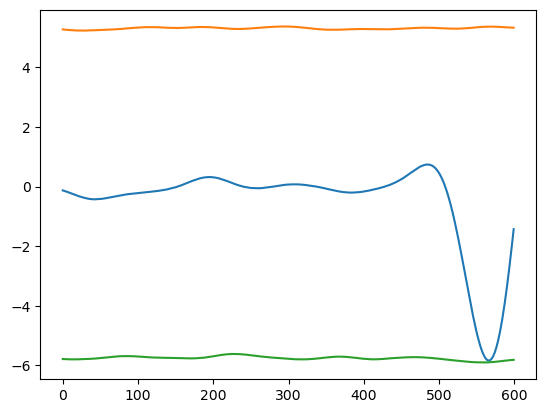

In [100]:
import matplotlib.pyplot as plt
plt.plot(pre_sta)
plt.plot(pre_prior + pre_error)
plt.plot(pre_prior - pre_error)

In [107]:
np.min(pre_sta)

np.float64(-1.9273536536786866)

In [105]:
t = np.where(pre_sta == np.min(pre_sta))
t[0]

array([566])

In [108]:
(pre_prior - pre_error)[t[0]]

array([-1.94648043])

In [ ]:
stim_dir = './dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/'

# degree moths only (m11 is volts → excluded from angle stats)
deg_files = sorted(glob.glob(stim_dir + '*_timeStamps_degrees.pickle'))

mins, maxs = [], []
for fp in deg_files:
    with open(fp, 'rb') as f:
        wn = np.asarray(pickle.load(f)[2]).ravel()    # index 2 = WhiteNoise (the stimulus, in degrees)
    mins.append(wn.min())
    maxs.append(wn.max())
    print(f'{os.path.basename(fp)}: {wn.min():.3f} to {wn.max():.3f} deg')

print(f'\nAngle range (degrees), n={len(deg_files)} moths:')
print(f'  global min {min(mins):.3f}')
print(f'  global max {max(maxs):.3f}')

In [ ]:
out_path = './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/'

deg_amp, volt_amp = [], []     # max-magnitude deflection per unit

for fp in sorted(glob.glob(out_path + '*_EncodingModel.pickle')):
    fname = os.path.basename(fp)
    with open(fp, 'rb') as f:
        sta = np.asarray(pickle.load(f)[1]).ravel()    # index 1 = STA
    pre = sta[:600]                                    # pre-spike only
    amp = np.abs(pre).max()                            # largest deflection, neg or pos

    if fname.startswith('m11'):
        volt_amp.append(amp)
    else:
        deg_amp.append(amp)
    print(f'{fname}: max amplitude {amp:.4f}')

deg_amp, volt_amp = np.array(deg_amp), np.array(volt_amp)

print(f'\nSTA max amplitude — DEGREES group, n={len(deg_amp)} units:')
print(f'  mean {deg_amp.mean():.4f}   std {deg_amp.std(ddof=1):.4f}')

print(f'\nSTA max amplitude — VOLTS group (m11), n={len(volt_amp)} units:')
print(f'  mean {volt_amp.mean():.4f}   std {volt_amp.std(ddof=1):.4f}')

In [ ]:
import statistics

values = [1.70, 0.03, 0.87, 0.60, 1.03, 1.13, 1.33, 1.23]

std_dev = statistics.stdev(values)
print(f"Sample Standard Deviation: {std_dev:.2f}")
